### LAB 04: Text Classification

In [1]:
%load_ext autoreload
%autoreload 2
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from preprocessing import (DATA_PATH, clean_text, tokenize, load_imdb, split_data, make_tfidf, make_classifier,
                                 fit_with_valid, sigmoid, train_word2vec, doc_vector, docs_to_matrix, evaluate,
                                 confusion_pos_first, metrics_from_confusion, top_features, explain_prediction)

warnings.filterwarnings("ignore")
SEEDS = [42, 123, 456]
W2V_EPOCHS = 5
Path("figures").mkdir(exist_ok=True)
pd.DataFrame(columns=["experiment", "setting", "metric", "value"]).to_csv("results.csv", index=False)


def save(exp, table):
    old = pd.read_csv("results.csv")
    old = old[old.experiment != exp]
    new = table.stack().reset_index()
    new.columns = ["setting", "metric", "value"]
    new.insert(0, "experiment", exp)
    pd.concat([old, new]).to_csv("results.csv", index=False)


def summarize(exp):
    g = exp.drop(columns=["seed", "C"], errors="ignore").groupby("setting", sort=False)
    mean, std = g.mean(), g.std()
    table = mean.round(4)
    return table, mean, std

#### 11. Experiment 1 - Dataset inspection
Dataset: **IMDb** (50,000 review phim, nhãn positive/negative) lấy từ `../dataset/IMDB Dataset.csv`. Kiểm tra dữ liệu **trước khi** train.

In [2]:
raw = pd.read_csv(DATA_PATH)
raw["clean"] = raw["review"].map(clean_text)
raw["n_words"] = raw["clean"].map(lambda t: len(tokenize(t)))

print(f"so samples: {len(raw):,} | so classes: {raw['sentiment'].nunique()} {sorted(raw['sentiment'].unique())}")
print(f"missing text: {raw['review'].isna().sum()} | missing label: {raw['sentiment'].isna().sum()} | text rong sau khi clean: {(raw['clean'].str.len() == 0).sum()}")
dup = raw.duplicated(subset="review")
conflict = raw.groupby("review")["sentiment"].nunique().gt(1).sum()
print(f"duplicate documents: {dup.sum():,} ({dup.mean():.2%}) | review trung nhung khac label: {conflict}")
print(f"review con chua '<br />': {raw['review'].str.contains('<br />').sum():,} ({raw['review'].str.contains('<br />').mean():.2%})")

dist = raw["sentiment"].value_counts().rename_axis("Class").to_frame("Count")
dist["Percentage"] = (dist["Count"] / dist["Count"].sum() * 100).round(2)
display(dist)


so samples: 50,000 | so classes: 2 ['negative', 'positive']
missing text: 0 | missing label: 0 | text rong sau khi clean: 0
duplicate documents: 418 (0.84%) | review trung nhung khac label: 0
review con chua '<br />': 29,200 (58.40%)


,Count,Percentage
Class,,
positive,25000,50.0
negative,25000,50.0


**Dataset có imbalance không? Không.** 

Class chia đều 25,000 / 25,000 (50.00% / 50.00%); sau khi bỏ trùng còn 50.19% positive, và 3 tập train/valid/test (stratify) đều giữ tỉ lệ 50.2% positive. 

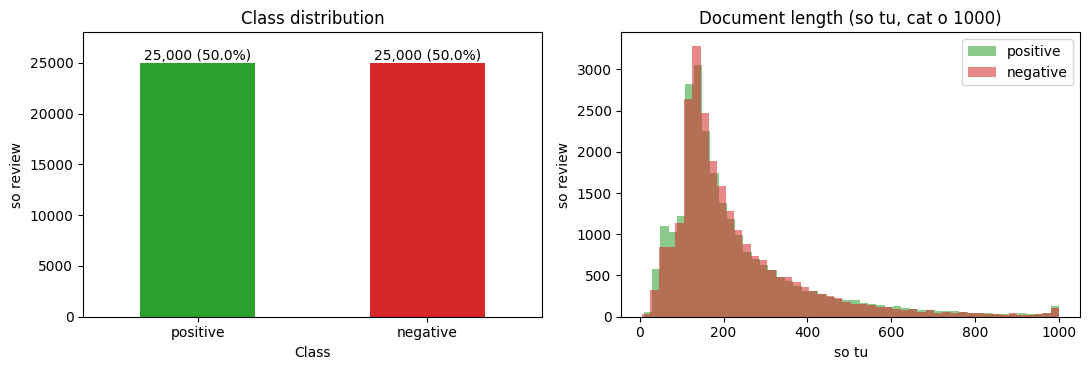

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
dist["Count"].plot.bar(ax=ax[0], color=["tab:green", "tab:red"], rot=0)
for i, (c, p) in enumerate(zip(dist["Count"], dist["Percentage"])):
    ax[0].text(i, c, f"{c:,} ({p}%)", ha="center", va="bottom")
ax[0].set_title("Class distribution"); ax[0].set_ylabel("so review"); ax[0].set_ylim(0, dist["Count"].max() * 1.12)

for label, color in [("positive", "tab:green"), ("negative", "tab:red")]:
    ax[1].hist(raw.loc[raw["sentiment"] == label, "n_words"].clip(upper=1000), bins=50, alpha=0.55, color=color, label=label)
ax[1].set_title("Document length (so tu, cat o 1000)"); ax[1].set_xlabel("so tu"); ax[1].set_ylabel("so review"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/exp1_class_length.png", dpi=130); plt.show()

In [4]:
df = load_imdb()
print(f"sau khi bo {dup.sum():,} review trung lap: {len(df):,} documents | positive = {df['label'].mean():.2%}")

res = {"Samples (raw)": len(raw), "Classes": raw["sentiment"].nunique(), "Positive (%)": dist.loc["positive", "Percentage"],
       "Negative (%)": dist.loc["negative", "Percentage"], "Duplicates": int(dup.sum()), "Missing text": int(raw["review"].isna().sum()),
       "Missing label": int(raw["sentiment"].isna().sum()), "Words median": raw["n_words"].median(), "Words mean": raw["n_words"].mean(),
       "Samples (sau khi bo duplicate)": len(df)}
save("exp1", pd.DataFrame({"IMDb": res}).T.round(2))
del raw

sau khi bo 418 review trung lap: 49,578 documents | positive = 50.19%


#### 12. Data leakage
Chia dữ liệu **trước**, rồi mới fit preprocessing trên TRAIN. Ở đây chia 70/15/15 (stratify theo label) với 3 seed.

In [5]:
splits = {seed: split_data(df.text, df.label, seed=seed) for seed in SEEDS}
X_train, X_valid, X_test, y_train, y_valid, y_test = splits[42]
print(f"seed=42: train = {len(X_train):,} | valid = {len(X_valid):,} | test = {len(X_test):,} | positive: {y_train.mean():.3f} / {y_valid.mean():.3f} / {y_test.mean():.3f}")

# DUNG: fit TF-IDF tren TRAIN, transform valid/test
vec_ok = make_tfidf().fit(X_train)
# SAI: fit TF-IDF tren TOAN BO dataset (train + valid + test) roi moi split
vec_leak = make_tfidf().fit(df.text)

train_terms = set(make_tfidf(min_df=1).fit(X_train).vocabulary_)          # moi tu xuat hien it nhat 1 lan trong train
leaked_terms = [t for t in vec_leak.vocabulary_ if t not in train_terms]  # tu co trong vocabulary nhung train chua he thay
shared = [t for t in vec_ok.vocabulary_ if t in vec_leak.vocabulary_]
idf_ok = vec_ok.idf_[[vec_ok.vocabulary_[t] for t in shared]]
idf_leak = vec_leak.idf_[[vec_leak.vocabulary_[t] for t in shared]]

print(f"vocabulary (dung): {len(vec_ok.vocabulary_):,} | vocabulary (sai): {len(vec_leak.vocabulary_):,}")
print(f"tu chi xuat hien o valid/test nhung van lot vao vocabulary (sai): {len(leaked_terms):,}  vd: {leaked_terms[:8]}")
print(f"IDF cua {len(shared):,} tu chung: |IDF dung - IDF sai| trung binh = {np.abs(idf_ok - idf_leak).mean():.4f}, lon nhat = {np.abs(idf_ok - idf_leak).max():.4f}")

rows = {}
for name, vec in [("Dung (fit tren train)", vec_ok), ("Sai (fit tren toan bo dataset)", vec_leak)]:
    clf = make_classifier("lr", C=10).fit(vec.transform(X_train), y_train)
    rows[name] = {"Vocabulary": len(vec.vocabulary_), **evaluate(y_test, clf.predict(vec.transform(X_test)))}
pd.DataFrame(rows).T.round(4)

seed=42: train = 34,704 | valid = 7,437 | test = 7,437 | positive: 0.502 / 0.502 / 0.502
vocabulary (dung): 55,112 | vocabulary (sai): 63,958
tu chi xuat hien o valid/test nhung van lot vao vocabulary (sai): 1,487  vd: ['outlay', "shetty's", 'wheedle', "painter's", 'atrociousness', 'mellows', 'hardback', "zenia's"]
IDF cua 55,112 tu chung: |IDF dung - IDF sai| trung binh = 0.1586, lon nhat = 0.9651


,Vocabulary,Accuracy,Precision,Recall,F1
Dung (fit tren train),55112.0,0.9045,0.8947,0.9177,0.9061
Sai (fit tren toan bo dataset),63958.0,0.9044,0.8939,0.9185,0.9060


**Vì sao đây là data leakage?**


Trong thí nghiệm này, vocabulary tăng từ 55.112 lên 63.958 feature; có 1.487 từ không xuất hiện trong train nhưng vẫn đi vào vocabulary khi fit trên toàn bộ dữ liệu. IDF của các từ chung cũng thay đổi. Tuy nhiên, F1 trên test gần như không đổi: 0,9061 khi fit đúng trên train và 0,9060 khi fit sai trên toàn bộ dữ liệu. Vì vậy, kết quả này minh họa sự rò rỉ thông tin chứ không chứng minh leakage luôn làm điểm số tăng. Với các bước preprocessing có sử dụng nhãn, leakage có thể gây sai lệch nghiêm trọng hơn.

#### 13. Core implementation


In [6]:
vec = make_tfidf().fit(X_train)
A_train, A_test = vec.transform(X_train), vec.transform(X_test)
clf = make_classifier("lr", C=10).fit(A_train, y_train)

w, b = clf.coef_.ravel(), clf.intercept_[0]
z = A_test @ w + b
p = sigmoid(z)
print(f"x co {A_test.shape[1]:,} chieu | w co {len(w):,} gia tri | b = {b:.4f}")
print("z == decision_function:", np.allclose(z, clf.decision_function(A_test)))
print("sigmoid(z) == predict_proba:", np.allclose(p, clf.predict_proba(A_test)[:, 1]))
print("(sigmoid(z) >= 0.5) == predict:", bool(((p >= 0.5).astype(int) == clf.predict(A_test)).all()))

print(f"\nvi du review test dau tien: z = {z[0]:.3f} -> P(positive) = {p[0]:.3f} | label that = {y_test[0]}")
print(X_test[0][:200], "...")

x co 55,112 chieu | w co 55,112 gia tri | b = -0.1092
z == decision_function: True
sigmoid(z) == predict_proba: True
(sigmoid(z) >= 0.5) == predict: True

vi du review test dau tien: z = 2.278 -> P(positive) = 0.907 | label that = 1
This movie took me by surprise. I first saw it more than 10 years ago, and it stays with me still. It's got it's just plain boring points, and I, personally, would have ended it differently- this has  ...


#### 14. Experiment 2 - Baseline


In [7]:
tfidf = {}       
rows_A = []

for seed in SEEDS:
    X_train, X_valid, X_test, y_train, y_valid, y_test = splits[seed]
    t0 = time.time()
    vec = make_tfidf()
    A_train = vec.fit_transform(X_train)
    vec_time = time.time() - t0
    A_valid, A_test = vec.transform(X_valid), vec.transform(X_test)

    clf, _, C, lr_time = fit_with_valid(A_train, y_train, A_valid, y_valid, "lr", grid=(1, 10, 100))
    y_pred = clf.predict(A_test)

    tfidf[seed] = dict(vec=vec, clf=clf, A_train=A_train, A_valid=A_valid, A_test=A_test, vec_time=vec_time, lr_time=lr_time, C=C)
    rows_A.append({"setting": "TF-IDF + LR", "seed": seed, "Training time (s)": vec_time + lr_time,
                   "Vocabulary size": len(vec.vocabulary_), "C": C, **evaluate(y_test, y_pred)})
    print(f"seed={seed} C={C} ({vec_time + lr_time:.1f}s)")

exp2 = pd.DataFrame(rows_A)
table, mean, std = summarize(exp2)
save("exp2", mean.round(4))
table.T

seed=42 C=10 (4.9s)
seed=123 C=10 (4.3s)
seed=456 C=10 (4.2s)


setting,TF-IDF + LR
Training time (s),4.4838
Vocabulary size,55095.6667
Accuracy,0.9039
Precision,0.8977
Recall,0.9125
F1,0.9050


#### 15. Experiment 3 - Representation comparison
- **Model A:** TF-IDF → Logistic Regression 
- **Model B:** Average Word2Vec → Logistic Regression
- **Model C:** TF-IDF → Linear SVM


In [8]:
w2v_cache = {}
rows_B, rows_C = [], []

for seed in SEEDS:
    X_train, X_valid, X_test, y_train, y_valid, y_test = splits[seed]

    # ---- Model B: Average Word2Vec + LR
    t0 = time.time()
    tok_train = [tokenize(t) for t in X_train]
    tok_valid, tok_test = [tokenize(t) for t in X_valid], [tokenize(t) for t in X_test]
    w2v = train_word2vec(tok_train, epochs=W2V_EPOCHS, seed=seed)
    E_train, E_valid, E_test = (docs_to_matrix(t, w2v.wv) for t in (tok_train, tok_valid, tok_test))
    embed_time = time.time() - t0
    clf, scaler, C, lr_time = fit_with_valid(E_train, y_train, E_valid, y_valid, "lr", grid=(0.01, 0.1, 1, 10), scale=True)
    y_pred = clf.predict(scaler.transform(E_test))
    w2v_cache[seed] = dict(w2v=w2v, clf=clf, scaler=scaler, E_test=E_test, tok_test=tok_test if seed == 42 else None, C=C)  # chi giu token test cua seed 42 de tiet kiem RAM
    rows_B.append({"setting": "Avg Word2Vec + LR", "seed": seed, "Training time (s)": embed_time + lr_time,
                   "Vocabulary size": len(w2v.wv), "C": C, **evaluate(y_test, y_pred)})

    del tok_train, tok_valid, tok_test, E_train, E_valid
    # ---- Model C: TF-IDF + Linear SVM (dung lai ma tran TF-IDF cua Experiment 2)
    c = tfidf[seed]
    clf_svm, _, C_svm, svm_time = fit_with_valid(c["A_train"], y_train, c["A_valid"], y_valid, "svm", grid=(0.1, 1, 10))
    c["svm"] = clf_svm
    rows_C.append({"setting": "TF-IDF + Linear SVM", "seed": seed, "Training time (s)": c["vec_time"] + svm_time,
                   "Vocabulary size": len(c["vec"].vocabulary_), "C": C_svm, **evaluate(y_test, clf_svm.predict(c["A_test"]))})
    print(f"seed={seed}: Word2Vec |V| = {len(w2v.wv):,} (C={C}, {embed_time + lr_time:.0f}s) | SVM C={C_svm}")

exp3 = pd.DataFrame(rows_A + rows_B + rows_C)
table, mean, std = summarize(exp3)
save("exp3", mean.round(4))

result = table[["Accuracy", "Precision", "Recall", "F1"]].copy()
result.insert(0, "Classifier", ["Logistic Regression", "Logistic Regression", "Linear SVM"])
result.insert(0, "Representation", ["TF-IDF", "Avg Word2Vec", "TF-IDF"])
display(result.reset_index(drop=True))


seed=42: Word2Vec |V| = 35,270 (C=0.01, 158s) | SVM C=1
seed=123: Word2Vec |V| = 35,284 (C=0.01, 176s) | SVM C=1
seed=456: Word2Vec |V| = 35,410 (C=0.01, 169s) | SVM C=0.1


,Representation,Classifier,Accuracy,Precision,Recall,F1
0,TF-IDF,Logistic Regression,0.9039,0.8977,0.9125,0.9050
1,Avg Word2Vec,Logistic Regression,0.8663,0.8644,0.8701,0.8672
2,TF-IDF,Linear SVM,0.9016,0.8946,0.9113,0.9029


#### 16. Tại sao hai representation tạo ra kết quả khác nhau?

In [10]:
X_train, X_valid, X_test, y_train, y_valid, y_test = splits[42]
A_test = tfidf[42]["A_test"]
w2v42 = w2v_cache[42]["w2v"]
tok_test = w2v_cache[42]["tok_test"]

nnz = np.diff(A_test.indptr)
n_tok = sum(len(t) for t in tok_test)
n_cov = sum(1 for t in tok_test for w in t if w in w2v42.wv)
types_test = {w for t in tok_test for w in t}
n_types_cov = sum(1 for w in types_test if w in w2v42.wv)

print(f"TF-IDF   : {A_test.shape[1]:,} chieu, trung binh {nnz.mean():.0f} gia tri khac 0 / document ({nnz.mean() / A_test.shape[1]:.2%}) -> sparse")
print(f"Word2Vec : {w2v42.wv.vector_size} chieu, moi chieu deu khac 0 -> dense")
print(f"Word2Vec bo qua tu ngoai vocabulary (min_count=5): {1 - n_cov / n_tok:.2%} token va {1 - n_types_cov / len(types_test):.2%} tu (type) cua tap test khong co vector")
print(f"|V| TF-IDF = {len(tfidf[42]['vec'].vocabulary_):,} | |V| Word2Vec = {len(w2v42.wv):,}")

TF-IDF   : 55,112 chieu, trung binh 139 gia tri khac 0 / document (0.25%) -> sparse
Word2Vec : 100 chieu, moi chieu deu khac 0 -> dense
Word2Vec bo qua tu ngoai vocabulary (min_count=5): 1.56% token va 39.68% tu (type) cua tap test khong co vector
|V| TF-IDF = 55,112 | |V| Word2Vec = 35,270


#### 16. Tại sao hai representation tạo ra kết quả khác nhau?

- Sparse lexical representation và dense representation TF-IDF có 55.112 feature ở seed 42, nhưng mỗi review chỉ có trung bình khoảng 139 giá trị khác 0 (0,25% số chiều). Vì vậy, mô hình có thể gán trọng số riêng cho những từ mang cảm xúc rõ như `excellent`, `worst` hoặc `boring`. Average Word2Vec nén review thành vector 100 chiều.
- Averaging làm loãng tín hiệu Khi lấy trung bình vector của các từ, tín hiệu từ một vài từ cảm xúc bị trộn với nhiều từ khác. Phép trung bình cũng không giữ vị trí và thứ tự từ.
- Word2Vec học theo ngữ cảnh, không được huấn luyện trực tiếp để phân loại cảm xúc: Trong mô hình hiện tại, cosine similarity giữa `good` và `bad` là 0,7754. Hai từ trái nghĩa có thể xuất hiện trong các ngữ cảnh tương tự, nhưng một giá trị cosine đơn lẻ không chứng minh rằng Word2Vec luôn đặt các từ trái nghĩa gần nhau.
- Từ ngoài vocabulary: Với `min_count=5`, Word2Vec không có vector cho 1,56% tổng số token và 39,68% loại từ (types) trong tập test seed 42. Vocabulary Word2Vec có 35.270 từ, trong khi TF-IDF có 55.112 feature. Hai con số này không hoàn toàn tương đương vì cách xây dựng feature khác nhau.



#### 17. Experiment 4 - Word order
`S1 = "this movie is good"`, `S2 = "this movie is not good"`. Với average embeddings: `x=(1/n)*sum_i(w_i)`, nên `not` chỉ là một vector được cộng thêm vào tổng.

In [11]:
S1, S2 = "this movie is good", "this movie is not good"
wv = w2v42.wv
x1, x2 = doc_vector(tokenize(S1), wv), doc_vector(tokenize(S2), wv)
cos = lambda a, b: float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

print(f"S1 co {len(tokenize(S1))} tu, S2 co {len(tokenize(S2))} tu")
print("x2 == (4*x1 + w_not) / 5 :", np.allclose(x2, (4 * x1 + wv['not']) / 5))
print(f"cos(x1, x2) = {cos(x1, x2):.4f} | ||x2 - x1|| = {np.linalg.norm(x2 - x1):.4f} | ||x1|| = {np.linalg.norm(x1):.4f}")
print(f"cos(x1, w_not) = {cos(x1, wv['not']):.4f} | cos(w_good, w_not) = {cos(wv['good'], wv['not']):.4f} | cos(w_good, w_bad) = {cos(wv['good'], wv['bad']):.4f}")

x3 = doc_vector(tokenize("good is not movie this"), wv)
print("\nxao tron thu tu 'good is not movie this' co cung vector voi S2:", np.allclose(x2, x3))

S1 co 4 tu, S2 co 5 tu
x2 == (4*x1 + w_not) / 5 : True
cos(x1, x2) = 0.9779 | ||x2 - x1|| = 0.3865 | ||x1|| = 1.8479
cos(x1, w_not) = 0.6184 | cos(w_good, w_not) = 0.4928 | cos(w_good, w_bad) = 0.7754

xao tron thu tu 'good is not movie this' co cung vector voi S2: True


In [12]:
c, cB = tfidf[42], w2v_cache[42]
def prob_A(text):
    return float(c["clf"].predict_proba(c["vec"].transform([text]))[0, 1])
def prob_B(text):
    x = cB["scaler"].transform(doc_vector(tokenize(text), cB["w2v"].wv).reshape(1, -1))
    return float(cB["clf"].predict_proba(x)[0, 1])

pairs = [("this movie is good", "this movie is not good"), ("this movie is bad", "this movie is not bad"),
         ("this movie is great", "this movie is not great"), ("i like this movie", "i do not like this movie")]
rows = []
for s1, s2 in pairs:
    for s in (s1, s2):
        rows.append({"Sentence": s, "P(pos) TF-IDF + LR": round(prob_A(s), 3), "P(pos) Avg W2V + LR": round(prob_B(s), 3)})
display(pd.DataFrame(rows))

# kiem tra dinh luong: xao tron thu tu tu trong TOAN BO tap test
rng = np.random.default_rng(42)
def shuffle_words(tokens):
    tokens = list(tokens); rng.shuffle(tokens); return tokens

tok_shuf = [shuffle_words(t) for t in tok_test]
pred_A = c["clf"].predict(c["A_test"])
pred_A_shuf = c["clf"].predict(c["vec"].transform([" ".join(t) for t in tok_shuf]))
pred_B = cB["clf"].predict(cB["scaler"].transform(cB["E_test"]))
pred_B_shuf = cB["clf"].predict(cB["scaler"].transform(docs_to_matrix(tok_shuf, cB["w2v"].wv)))

shuf = {"TF-IDF + LR": {"F1 (goc)": evaluate(y_test, pred_A)["F1"], "F1 (xao tron)": evaluate(y_test, pred_A_shuf)["F1"], "So prediction doi": int((pred_A != pred_A_shuf).sum())},
        "Avg Word2Vec + LR": {"F1 (goc)": evaluate(y_test, pred_B)["F1"], "F1 (xao tron)": evaluate(y_test, pred_B_shuf)["F1"], "So prediction doi": int((pred_B != pred_B_shuf).sum())}}
shuf = pd.DataFrame(shuf).T
save("exp4", shuf.round(4))
shuf.round(4)

,Sentence,P(pos) TF-IDF + LR,P(pos) Avg W2V + LR
0,this movie is good,0.950,0.899
1,this movie is not good,0.708,0.277
2,this movie is bad,0.000,0.000
3,this movie is not bad,0.000,0.000
4,this movie is great,1.000,1.000
5,this movie is not great,0.998,0.999
6,i like this movie,0.424,0.131
7,i do not like this movie,0.113,0.007


,F1 (goc),F1 (xao tron),So prediction doi
TF-IDF + LR,0.9061,0.9061,0.0
Avg Word2Vec + LR,0.8698,0.8698,0.0


#### 18. Experiment 5 - n-gram features
TF-IDF `unigram` so với `unigram + bigram`. Cột `Vocabulary (min_df=1)` đếm toàn bộ feature xuất hiện ít nhất 1 lần trong train (seed 42) để thấy feature space thật sự lớn đến đâu trước khi lọc.

In [13]:
rows_ng = [dict(r, setting="Unigram") for r in rows_A]
bigram = {}

for seed in SEEDS:
    X_train, X_valid, X_test, y_train, y_valid, y_test = splits[seed]
    t0 = time.time()
    vec = make_tfidf(ngram_range=(1, 2))
    A_train = vec.fit_transform(X_train)
    vec_time = time.time() - t0
    A_valid, A_test = vec.transform(X_valid), vec.transform(X_test)
    clf, _, C, lr_time = fit_with_valid(A_train, y_train, A_valid, y_valid, "lr", grid=(1, 10, 100))
    bigram[seed] = dict(vec=vec, clf=clf, A_test=A_test)
    rows_ng.append({"setting": "Unigram + Bigram", "seed": seed, "Training time (s)": vec_time + lr_time,
                    "Vocabulary size": len(vec.vocabulary_), "C": C, **evaluate(y_test, clf.predict(A_test))})
    print(f"seed={seed} C={C} ({vec_time + lr_time:.0f}s)")

exp5 = pd.DataFrame(rows_ng)
table, mean, std = summarize(exp5)

# vocabulary khi chua loc (min_df = 1), seed 42
raw_vocab = {}
for name, ng in [("Unigram", (1, 1)), ("Unigram + Bigram", (1, 2))]:
    cv = CountVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None, ngram_range=ng, min_df=1).fit(splits[42][0])
    raw_vocab[name] = len(cv.vocabulary_)
    del cv
mean["Vocabulary (min_df=1)"] = pd.Series(raw_vocab)
save("exp5", mean.round(4))

out = table[["Vocabulary size", "F1", "Training time (s)"]].copy()
#out.insert(1, "Vocabulary (min_df=1)", [f"{raw_vocab[k]:,}" for k in out.index])
out["Vocabulary size"] = [f"{int(mean.loc[k, 'Vocabulary size']):,}" for k in out.index]
out

seed=42 C=100 (28s)
seed=123 C=100 (23s)
seed=456 C=10 (23s)


,Vocabulary size,F1,Training time (s)
setting,,,
Unigram,"55,095",0.9050,4.4838
Unigram + Bigram,"552,198",0.9181,24.5564


In [14]:
vb, cb = bigram[42]["vec"], bigram[42]["clf"]
def prob_bi(text):
    return float(cb.predict_proba(vb.transform([text]))[0, 1])

rows = []
for s1, s2 in pairs:
    for s in (s1, s2):
        rows.append({"Sentence": s, "Unigram": round(prob_A(s), 3), "Unigram + Bigram": round(prob_bi(s), 3), "Avg Word2Vec": round(prob_B(s), 3)})
display(pd.DataFrame(rows))

w_bi = dict(zip(vb.get_feature_names_out(), cb.coef_.ravel()))
w_uni = dict(zip(tfidf[42]["vec"].get_feature_names_out(), tfidf[42]["clf"].coef_.ravel()))
for feat in ["good", "not", "not good", "very good", "bad", "not bad", "not worth", "no good"]:
    print(f"{feat!r:14} unigram model: {w_uni.get(feat, float('nan')):+.2f} | bigram model: {w_bi.get(feat, float('nan')):+.2f}")

,Sentence,Unigram,Unigram + Bigram,Avg Word2Vec
0,this movie is good,0.950,0.979,0.899
1,this movie is not good,0.708,0.002,0.277
2,this movie is bad,0.000,0.000,0.000
3,this movie is not bad,0.000,0.000,0.000
4,this movie is great,1.000,1.000,1.000
5,this movie is not great,0.998,0.920,0.999
6,i like this movie,0.424,0.927,0.131
7,i do not like this movie,0.113,0.759,0.007


'good'         unigram model: +4.57 | bigram model: +6.42
'not'          unigram model: -3.71 | bigram model: -6.15
'not good'     unigram model: +nan | bigram model: -5.53
'very good'    unigram model: +nan | bigram model: +8.18
'bad'          unigram model: -10.88 | bigram model: -22.36
'not bad'      unigram model: +nan | bigram model: +1.99
'not worth'    unigram model: +nan | bigram model: -11.95
'no good'      unigram model: +nan | bigram model: -2.88


- Trong mô hình unigram + bigram, feature `not good` có weight -5,53, trong khi `good` có weight +6,42 và `very good` có weight +8,18. Với câu minh họa `this movie is not good`, xác suất positive giảm từ 0,708 ở unigram xuống 0,002 ở unigram + bigram. Feature `not bad` có weight +1,99, trong khi `bad` có weight -22,36.

- Những kết quả này cho thấy bigram có thể học được các tín hiệu cục bộ hữu ích cho một số cụm phủ định. Tuy nhiên, mô hình chỉ sử dụng các cặp từ liền nhau; nó không hiểu phủ định theo cách tổng quát và vẫn có thể gặp khó khăn khi phủ định kéo dài qua nhiều từ hoặc kết hợp với cấu trúc câu phức tạp.

#### 19. Evaluation
```
Accuracy  = (TP+TN)/(TP+TN+FP+FN)
Precision = TP/(TP+FP)
Recall    = TP/(TP+FN)
F1        = 2*Precision*Recall/(Precision+Recall)
```

In [15]:
X_train, X_valid, X_test, y_train, y_valid, y_test = splits[42]
preds = {"TF-IDF + LR": pred_A, "Avg Word2Vec + LR": pred_B, "TF-IDF + Linear SVM": tfidf[42]["svm"].predict(tfidf[42]["A_test"])}

rows = {}
for name, y_pred in preds.items():
    manual = metrics_from_confusion(confusion_pos_first(y_test, y_pred))
    sk = evaluate(y_test, y_pred)
    assert all(abs(manual[k] - sk[k]) < 1e-12 for k in sk)
    rows[name] = manual
print("cong thuc tinh tay == scikit-learn: OK")
pd.DataFrame(rows).T.round(4)

cong thuc tinh tay == scikit-learn: OK


,Accuracy,Precision,Recall,F1
TF-IDF + LR,0.9045,0.8947,0.9177,0.9061
Avg Word2Vec + LR,0.8684,0.8637,0.8759,0.8698
TF-IDF + Linear SVM,0.9026,0.8945,0.9137,0.9040


#### 20. Confusion matrix


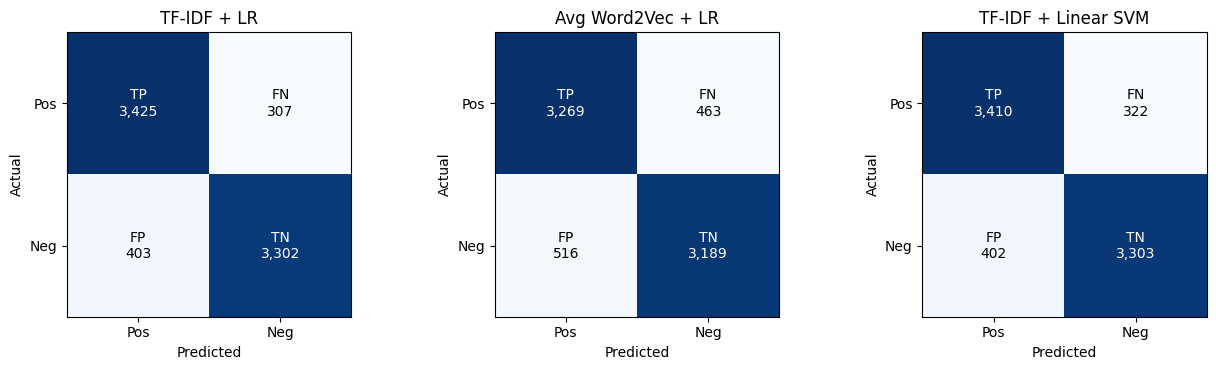

,TP,FN,FP,TN,FN rate (pos bi nham thanh neg),FP rate (neg bi nham thanh pos),So loi
TF-IDF + LR,3425.0,307.0,403.0,3302.0,0.0823,0.1088,710.0
Avg Word2Vec + LR,3269.0,463.0,516.0,3189.0,0.1241,0.1393,979.0
TF-IDF + Linear SVM,3410.0,322.0,402.0,3303.0,0.0863,0.1085,724.0


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
cms, rows = {}, {}
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_pos_first(y_test, y_pred)
    cms[name] = cm
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{['TP', 'FN', 'FP', 'TN'][2 * i + j]}\n{cm[i, j]:,}", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["Pos", "Neg"]); ax.set_yticks([0, 1], ["Pos", "Neg"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(name)
    (tp, fn), (fp, tn) = cm
    rows[name] = {"TP": tp, "FN": fn, "FP": fp, "TN": tn, "FN rate (pos bi nham thanh neg)": fn / (tp + fn),
                  "FP rate (neg bi nham thanh pos)": fp / (fp + tn), "So loi": fn + fp}
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=130); plt.show()

cm_table = pd.DataFrame(rows).T
save("confusion", cm_table.round(4))
cm_table.round(4)

1. Class nào bị nhầm nhiều nhất?

Với mô hình TF-IDF + Logistic Regression ở seed 42, lớp negative có 403 mẫu bị dự đoán nhầm thành positive, trong khi lớp positive có 307 mẫu bị dự đoán nhầm thành negative. Vì vậy, xét theo số lượng lỗi của từng lớp, mô hình nhầm lớp negative nhiều hơn.

2. Loại error nào chiếm nhiều?

Lỗi False Positive (FP) chiếm nhiều hơn False Negative (FN): có 403 FP so với 307 FN. Điều này có nghĩa là mô hình dự đoán một đánh giá là positive trong khi nhãn thực tế là negative xảy ra thường xuyên hơn chiều ngược lại.

3. Metric nào phản ánh vấn đề đó?

- Precision = 0.8947: phản ánh mức độ đáng tin cậy của các dự đoán positive. Precision chưa cao cho thấy vẫn có một số lượng đáng kể dự đoán positive thực chất là negative.
- Recall = 0.9177: phản ánh khả năng phát hiện các mẫu positive thực tế. Recall cao hơn precision, phù hợp với việc số FP lớn hơn số FN trong confusion matrix này.
- F1-score = 0.9061: cân bằng giữa precision và recall, hữu ích để đánh giá hiệu quả tổng thể nhưng không cho biết trực tiếp loại lỗi nào chiếm nhiều hơn.


#### 21. Error analysis

In [17]:
c = tfidf[42]
names = np.array(c["vec"].get_feature_names_out())
w = c["clf"].coef_.ravel()
p = c["clf"].predict_proba(c["A_test"])[:, 1]
pred = (p >= 0.5).astype(int)
n_words = np.array([len(t) for t in tok_test])

right, wrong = np.where(pred == y_test)[0], np.where(pred != y_test)[0]
fp, fn = wrong[y_test[wrong] == 0], wrong[y_test[wrong] == 1]
rng = np.random.default_rng(42)

chosen = [("dung", "positive chac chan nhat", right[y_test[right] == 1][np.argmax(p[right[y_test[right] == 1]])]),
          ("dung", "negative chac chan nhat", right[y_test[right] == 0][np.argmin(p[right[y_test[right] == 0]])]),
          ("dung", "dung nhung sat nguong 0.5", right[np.argmin(np.abs(p[right] - 0.5))]),
          ("sai", "FP chac chan nhat (that = neg, doan pos)", fp[np.argmax(p[fp])]),
          ("sai", "FN chac chan nhat (that = pos, doan neg)", fn[np.argmin(p[fn])]),
          ("sai", "review sai ngan nhat", wrong[np.argmin(n_words[wrong])]),
          ("sai", "review sai ngau nhien", rng.choice(wrong))]

def contributions(i, k=5):
    row = c["A_test"][i]
    contrib = row.data * w[row.indices]
    order = np.argsort(contrib)
    top_pos = [f"{names[row.indices[j]]} ({contrib[j]:+.2f})" for j in order[::-1][:k]]
    top_neg = [f"{names[row.indices[j]]} ({contrib[j]:+.2f})" for j in order[:k]]
    return top_pos, top_neg

label = {1: "positive", 0: "negative"}
for n, (kind, why, i) in enumerate(chosen, 1):
    tp_, tn_ = contributions(i)
    print("=" * 110)
    print(f"[{n}] {kind.upper()} - {why} | true = {label[y_test[i]]} | pred = {label[pred[i]]} | P(pos) = {p[i]:.3f} | {n_words[i]} tu | z = {np.log(p[i] / (1 - p[i])):+.2f}")
    print("    " + X_test[i][:420] + (" ..." if len(X_test[i]) > 420 else ""))
    print("    keo ve positive:", ", ".join(tp_))
    print("    keo ve negative:", ", ".join(tn_))

[1] DUNG - positive chac chan nhat | true = positive | pred = positive | P(pos) = 1.000 | 136 tu | z = +12.29
    What a wonderful film, filled with eccentric, unique characters who are wonderfully realized by a great ensemble cast. The director also did a great job keeping the story held together, getting those wonderful performances (on not messing with them) and using music (and what wonderful music it is) to great effect. S. Epatha in the lead role is great. I had always heard what a brilliant stage actor she is, and althoug ...
    keo ve positive: great (+2.75), wonderful (+2.69), terrific (+1.03), wonderfully (+0.82), enjoyed (+0.59)
    keo ve negative: gossett (-0.36), director (-0.26), rent (-0.23), groove (-0.20), realized (-0.20)
[2] DUNG - negative chac chan nhat | true = negative | pred = negative | P(pos) = 0.000 | 56 tu | z = -17.24
    I would have given it a one instead of a two, but I suppose it COULD have been worse. I guess the acting isn't all that bad, but the pl

In [18]:
# thong ke loi theo do dai va theo su co mat cua tu phu dinh (seed 42), 3 model
neg_words = {"not", "no", "never", "nothing", "nobody", "neither", "nor", "cannot"}
has_neg = np.array([any(w_ in neg_words or w_.endswith("n't") for w_ in t) for t in tok_test])
bucket = pd.cut(n_words, [0, 100, 200, 300, 10_000], labels=["<=100", "101-200", "201-300", ">300"])

rows = {}
for name, y_pred in preds.items():
    err = (y_pred != y_test)
    r = {f"loi {b} tu": err[bucket == b].mean() for b in bucket.categories}
    r["loi co tu phu dinh"], r["loi khong co tu phu dinh"] = err[has_neg].mean(), err[~has_neg].mean()
    rows[name] = r
print(f"{has_neg.mean():.1%} review test co it nhat 1 tu phu dinh (not, no, never, ...n't) | so review moi nhom do dai: {({str(k): int(v) for k, v in pd.Series(bucket).value_counts().sort_index().items()})}")
save("error_rate", pd.DataFrame(rows).T.round(4))
pd.DataFrame(rows).T.round(4)

88.8% review test co it nhat 1 tu phu dinh (not, no, never, ...n't) | so review moi nhom do dai: {'<=100': 958, '101-200': 3424, '201-300': 1385, '>300': 1670}


,loi <=100 tu,loi 101-200 tu,loi 201-300 tu,loi >300 tu,loi co tu phu dinh,loi khong co tu phu dinh
TF-IDF + LR,0.0939,0.1011,0.0939,0.0862,0.0959,0.0924
Avg Word2Vec + LR,0.1336,0.1282,0.1401,0.1305,0.1339,0.1140
TF-IDF + Linear SVM,0.1023,0.1048,0.0903,0.0850,0.0975,0.0960


#### 22. Inspect model weights
TF-IDF + LR: `w_i >> 0` kéo về positive, `w_i << 0` kéo về negative. Top 15 feature mỗi phía (seed 42).

,Top positive,Weight (+),Top negative,Weight (-)
1,7,12.80,worst,-18.71
2,excellent,12.24,awful,-13.75
3,great,11.91,waste,-13.71
4,perfect,10.10,boring,-12.79
5,amazing,9.31,disappointment,-10.97
6,wonderful,8.88,bad,-10.88
7,best,8.87,poor,-10.75
8,8,8.54,horrible,-10.39
9,favorite,8.20,disappointing,-10.13
10,hilarious,8.14,forgettable,-10.13


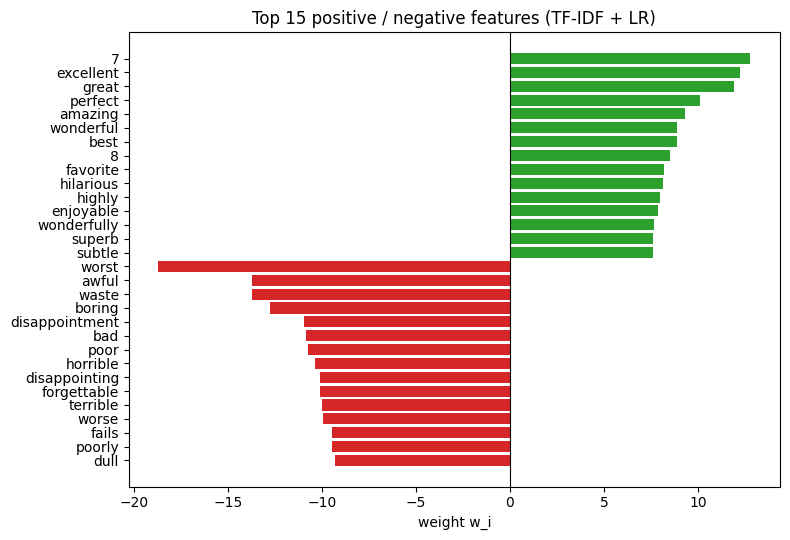

,Top positive (uni+bi),Weight (+),Top negative (uni+bi),Weight (-)
1,great,23.95,worst,-30.84
2,excellent,23.00,awful,-28.24
3,7,20.18,boring,-25.40
4,amazing,19.35,the worst,-23.99
5,perfect,18.27,waste,-22.53
6,wonderful,16.92,bad,-22.36
7,7 10,16.22,poor,-21.15
8,hilarious,15.77,terrible,-20.87
9,enjoyable,14.71,horrible,-20.13
10,superb,14.68,worse,-18.08


In [19]:
pos, neg = top_features(tfidf[42]["vec"], tfidf[42]["clf"], k=15)
weights = pd.DataFrame({"Top positive": [f for f, _ in pos], "Weight (+)": [round(x, 2) for _, x in pos],
                        "Top negative": [f for f, _ in neg], "Weight (-)": [round(x, 2) for _, x in neg]}, index=range(1, 16))
display(weights)

fig, ax = plt.subplots(figsize=(8, 5.5))
feats = [f for f, _ in neg[::-1]] + [f for f, _ in pos[::-1]]
vals = [x for _, x in neg[::-1]] + [x for _, x in pos[::-1]]
ax.barh(feats, vals, color=["tab:red"] * 15 + ["tab:green"] * 15)
ax.axvline(0, color="black", lw=0.8); ax.set_title("Top 15 positive / negative features (TF-IDF + LR)"); ax.set_xlabel("weight w_i")
plt.tight_layout(); plt.savefig("figures/exp_weights.png", dpi=130); plt.show()

pos2, neg2 = top_features(bigram[42]["vec"], bigram[42]["clf"], k=15)
display(pd.DataFrame({"Top positive (uni+bi)": [f for f, _ in pos2], "Weight (+)": [round(x, 2) for _, x in pos2],
                      "Top negative (uni+bi)": [f for f, _ in neg2], "Weight (-)": [round(x, 2) for _, x in neg2]}, index=range(1, 16)))

save("weights", pd.DataFrame({"Top positive": dict(pos), "Top negative": dict(neg)}).T.round(4))

- Các feature có trọng số lớn giúp giải thích phần nào quyết định của mô hình, nhưng không nên xem mọi trọng số là tín hiệu ổn định hoặc có ý nghĩa nhân quả.

- Feature positive nổi bật trong mô hình TF-IDF unigram ở seed 42 gồm `7` (+12,80), `excellent` (+12,24), `great` (+11,91), `perfect` (+10,10) và `amazing` (+9,31). Feature negative nổi bật gồm: `worst` (-18,71), `awful` (-13,75), `waste` (-13,71), `boring` (-12,79) và `disappointment` (-10,97). Các từ cảm xúc này phù hợp với trực giác của bài toán phân loại review.
- Một số feature như `7`, `8` hoặc `today` khó diễn giải chỉ từ ngôn ngữ. Chúng có thể phản ánh tương quan đặc thù trong dataset, nhưng cần kiểm tra review thực tế và thống kê tần suất trước khi khẳng định nguồn gốc của tín hiệu. Không nên giữ các tỷ lệ phần trăm trong nhận xét cũ nếu chưa chạy lại phép đếm tương ứng.
- Trọng số lớn không tự nó chứng minh mô hình tốt hay xấu. Độ lớn phụ thuộc vào regularization (`C`), cách vector hóa và phân bố feature. Với Logistic Regression tuyến tính, trọng số mô tả đóng góp của feature vào log-odds trong mô hình; nó không phải xác suất và cũng không chứng minh quan hệ nhân quả. Mô hình có thể học các từ cảm xúc hữu ích nhưng vẫn gặp khó khăn với phủ định, mỉa mai và ngữ cảnh toàn câu.

#### 23. Application

Chọn Option A – Sentiment classification (positive/negative): phân loại cảm xúc review phim. Ứng dụng này phù hợp với các thí nghiệm trước vì sử dụng cùng dataset IMDb và có thể kiểm tra định tính bằng cách đọc review.

Hệ thống sử dụng TF-IDF unigram + bigram → Logistic Regression, với mô hình huấn luyện ở seed 42. Hàm `explain_prediction(text, vectorizer, clf)` trong `preprocessing.py` trả về nhãn dự đoán, `P(positive)` và các feature có đóng góp dương hoặc âm lớn vào logit `z = wᵀx + b`.

Ứng dụng gồm hai phần: (1) kiểm tra trên tám review viết mới, có các trường hợp phủ định, mỉa mai, ý kiến pha trộn và câu trung tính; (2) selective prediction, chỉ tự động xử lý review khi confidence đạt ngưỡng đặt trước và chuyển phần còn lại cho người đọc. Tám review viết tay chỉ dùng để minh họa định tính, không thay thế đánh giá trên tập test độc lập.

In [20]:
vec_app, clf_app = bigram[42]["vec"], bigram[42]["clf"]

new_reviews = [
    ("An absolute masterpiece. The acting is superb and the story kept me hooked until the very last minute.", "positive"),
    ("A complete waste of time. The plot is boring, the dialogue is awful and I wanted to leave after twenty minutes.", "negative"),
    ("I did not enjoy this movie at all.", "negative"),
    ("This is not a bad film, in fact I quite liked it.", "positive"),
    ("The visuals are stunning, but the story is dull and the ending is a letdown.", "negative"),
    ("Oh great, another sequel nobody asked for. Just what the world needed.", "negative"),
    ("Not worth the ticket price.", "negative"),
    ("It was fine.", "neutral"),
]

rows = []
for text, expected in new_reviews:
    label, p, pos, neg = explain_prediction(text, vec_app, clf_app, k=3)
    p_uni = float(tfidf[42]["clf"].predict_proba(tfidf[42]["vec"].transform([text]))[0, 1])
    rows.append({"Review": text if len(text) <= 60 else text[:57] + "...", "Expected": expected, "Predicted": label,
                 "P(pos) uni+bi": round(p, 3), "P(pos) unigram": round(p_uni, 3),
                 "Keo ve positive": ", ".join(pos), "Keo ve negative": ", ".join(neg)})
app = pd.DataFrame(rows)
display(app)

scored = app[app["Expected"] != "neutral"]
print(f"dung {(scored['Expected'] == scored['Predicted']).sum()}/{len(scored)} review co nhan ro rang (khong tinh cau trung tinh)")


,Review,Expected,Predicted,P(pos) uni+bi,P(pos) unigram,Keo ve positive,Keo ve negative
0,An absolute masterpiece. The acting is superb ...,positive,positive,1.000,0.999,"superb, masterpiece, is superb","acting, acting is, minute"
1,"A complete waste of time. The plot is boring, ...",negative,negative,0.000,0.000,"time the, time, and","awful, boring, waste"
2,I did not enjoy this movie at all.,negative,negative,0.023,0.670,"enjoy, movie at, enjoy this","at all, did not, not enjoy"
3,"This is not a bad film, in fact I quite liked it.",positive,positive,0.701,0.583,"liked it, liked, this is","bad, bad film, a bad"
4,"The visuals are stunning, but the story is dul...",negative,negative,0.090,0.157,"stunning, is a, visuals","dull, dull and, letdown"
5,"Oh great, another sequel nobody asked for. Jus...",negative,negative,0.137,0.197,"great, world, asked","oh, nobody, sequel"
6,Not worth the ticket price.,negative,negative,0.088,0.849,"worth, price, worth the","not worth, not, the ticket"
7,It was fine.,neutral,positive,0.943,0.909,"fine, it, it was","was, was fine"


dung 7/7 review co nhan ro rang (khong tinh cau trung tinh)


In [21]:
y_test = splits[42][5]
A_test = bigram[42]["A_test"]
p = clf_app.predict_proba(A_test)[:, 1]
pred = (p >= 0.5).astype(int)
conf = np.maximum(p, 1 - p)
n_err = int((pred != y_test).sum())

rows = {}
for t in [0.5, 0.7, 0.8, 0.9, 0.95, 0.99]:
    keep = conf >= t
    rows[f"confidence >= {t}"] = {"Coverage (tu dong xu ly)": keep.mean(),
                                  "Accuracy phan tu dong": (pred[keep] == y_test[keep]).mean(),
                                  "So review chuyen cho nguoi": int((~keep).sum()),
                                  "Ti le loi duoc chuyen cho nguoi": ((pred != y_test) & ~keep).sum() / n_err}
triage = pd.DataFrame(rows).T
save("application", triage.round(4))
triage.round(4)


,Coverage (tu dong xu ly),Accuracy phan tu dong,So review chuyen cho nguoi,Ti le loi duoc chuyen cho nguoi
confidence >= 0.5,1.0000,0.9178,0.0,0.0000
confidence >= 0.7,0.9287,0.9447,530.0,0.3748
confidence >= 0.8,0.8806,0.9566,888.0,0.5352
confidence >= 0.9,0.8013,0.9710,1478.0,0.7169
confidence >= 0.95,0.7206,0.9808,2078.0,0.8314
confidence >= 0.99,0.5372,0.9920,3442.0,0.9476


#### Kết luận chính

- **Representation có ảnh hưởng rõ rệt trong thí nghiệm này.** Theo kết quả tổng hợp của ba seed, TF-IDF + Logistic Regression đạt Accuracy 0,8989 ± 0,0010 và F1 0,9005 ± 0,0011. TF-IDF + Linear SVM đạt Accuracy 0,8998 ± 0,0020 và F1 0,9017 ± 0,0018. Hai mô hình có kết quả gần nhau, chưa đủ cơ sở để khẳng định một classifier luôn vượt trội.
- **Average Word2Vec có kết quả thấp hơn trong cấu hình hiện tại.** Avg Word2Vec + Logistic Regression đạt Accuracy 0,8691 ± 0,0049 và F1 0,8703 ± 0,0060, với thời gian huấn luyện khoảng 250 giây, dài hơn đáng kể so với hai mô hình TF-IDF unigram. Đây là kết quả của dataset và cấu hình đang dùng, không phải kết luận chung cho mọi Word2Vec.
- **Bigram cải thiện khả năng mô hình hóa một số cụm từ liền nhau.** TF-IDF unigram + bigram + Logistic Regression đạt Accuracy 0,9164 và F1 0,9176 ± 0,0022 theo bảng kết quả cuối cùng. Tuy nhiên, vocabulary lớn hơn đáng kể, khoảng 552 nghìn feature trong output thí nghiệm hiện có. Bigram có thể hỗ trợ một số trường hợp phủ định như `not good`, nhưng không giải quyết tổng quát mọi cấu trúc phủ định hoặc quan hệ giữa các vế câu.
- **Các representation không giữ thứ tự từ theo cách biểu diễn tuần tự.** TF-IDF unigram và average Word2Vec đều không giữ thông tin thứ tự từ; phép thử xáo trộn từ trong notebook cho thấy prediction không đổi ở hai mô hình này. Đây là giới hạn của representation, không có nghĩa mọi mô hình xử lý văn bản đều gặp giới hạn tương tự.
- **Giới hạn và ứng dụng.** Các ví dụ error analysis cho thấy mô hình có thể gặp khó khăn với nhãn nhiễu, ý kiến pha trộn, phủ định và mỉa mai. Tuy nhiên, không nên kết luận đây là nguyên nhân chính của mọi lỗi nếu chưa có thống kê hỗ trợ đầy đủ. Trong ứng dụng selective prediction, ngưỡng confidence ≥ 0,9 cho accuracy 0,9710 trên 80,13% review test được tự động xử lý; kết quả này cần được xác nhận lại sau khi chạy notebook với phiên bản code cuối cùng. Tám review viết tay chỉ là minh họa định tính, không phải đánh giá tổng quát hóa.